## RAG with Tables and Images
Source file: `RAG_Table_Image.pdf`. It has normal text, a native table (page 1),
a bar chart image and a pricing table that is only a screenshot (page 2).

| Content | How it is indexed | What a query returns |
|---|---|---|
| Text | chunked + embedded | the text chunk |
| Native table | one vector per row + one summary vector, all pointing to the same table | the **whole table** |
| Image | Gemini vision describes it (chart values, tables inside the image), the description is embedded; the image file is saved locally | the **image itself** + its description |

At question time the matching text, tables and images are sent to Gemini, which answers from them.

### Step 1: Imports and configuration

In [15]:
import os
import hashlib
import pdfplumber
from pypdf import PdfReader
from dotenv import load_dotenv
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import SentenceTransformer
from pinecone import Pinecone, ServerlessSpec
from IPython.display import display, Markdown, Image
from google import genai
from google.genai import types

load_dotenv()

PDF_PATH = "RAG_Table_Image.pdf"
IMAGE_FOLDER = "RAG_Table_Image_assets"   # extracted images are saved here
NAMESPACE = "rag-table-image"
os.makedirs(IMAGE_FOLDER, exist_ok=True)

### Step 2: Connect to Pinecone

In [16]:
pc = Pinecone(api_key=os.getenv("PineCone_API_Key"))
index_name = os.getenv("Pinecone_Index_Name")

if index_name not in pc.list_indexes().names():
    pc.create_index(
        name=index_name,
        dimension=384,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1"),
    )
index = pc.Index(index_name)

### Step 3: Embedding model

In [17]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")


def embed(texts):
    return model.encode(texts)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5736.85it/s]


### Step 4: Gemini client
Used to describe images (vision) and to answer questions.

In [18]:
client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))
LLM_MODEL = "gemini-2.5-flash"


def ask_llm(content):
    """Gemini's text answer for a prompt (string or list of text / image parts), or None if it was blocked."""
    response = client.models.generate_content(model=LLM_MODEL, contents=content)
    return response.text


def image_block(path):
    with open(path, "rb") as f:
        return types.Part.from_bytes(data=f.read(), mime_type="image/png")

### Step 5: Extract native tables
Each table is kept as Markdown, with the line above it as its title.

In [19]:
def to_markdown(rows):
    rows = [[(c or "").replace("\n", " ").strip() for c in r] for r in rows]
    header, *body = rows
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(r) + " |" for r in body]
    return "\n".join(lines)


def table_title(page, table, page_no):
    above = page.crop((0, max(0, table.bbox[1] - 30), page.width, table.bbox[1])).extract_text() or ""
    return above.strip().split("\n")[-1] if above.strip() else f"Table on page {page_no}"


tables = []   # dict per table: id, page, title, rows, markdown
with pdfplumber.open(PDF_PATH) as pdf:
    for page_no, page in enumerate(pdf.pages, start=1):
        for n, t in enumerate(page.find_tables(), start=1):
            rows = [[(c or "").replace("\n", " ").strip() for c in r] for r in t.extract()]
            tables.append({
                "id": f"table-p{page_no}-{n}",
                "page": page_no,
                "title": table_title(page, t, page_no),
                "rows": rows,
                "markdown": to_markdown(rows),
                "bbox": t.bbox,
            })

for t in tables:
    print(t["id"], "|", t["title"])
    display(Markdown(t["markdown"]))

table-p1-1 | 2. Headcount and Budget by Department (Table 1)


| Department | Head | Employees | Budget (USD) | Location |
|---|---|---|---|---|
| Engineering | Priya Nair | 168 | $21,400,000 | Bengaluru |
| Sales | Marcus Lee | 92 | $11,750,000 | New York |
| Marketing | Elena Rossi | 47 | $6,200,000 | Milan |
| Customer Success | Tunde Okafor | 61 | $4,900,000 | Lagos |
| Finance | Hannah Kim | 22 | $2,300,000 | Seoul |
| HR | Diego Alvarez | 22 | $1,850,000 | Mexico City |
| Total |  | 412 | $48,400,000 |  |

### Step 6: Extract text (outside the tables, so table data isn't indexed twice) and chunk it

In [20]:
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50, separators=["\n\n", "\n", " ", ""])

text_chunks = []   # dict per chunk: id, page, text
with pdfplumber.open(PDF_PATH) as pdf:
    for page_no, page in enumerate(pdf.pages, start=1):
        for t in tables:
            if t["page"] == page_no:
                page = page.outside_bbox(t["bbox"])
        for i, chunk in enumerate(splitter.split_text(page.extract_text() or "")):
            text_chunks.append({"id": f"text-p{page_no}-{i}", "page": page_no, "text": chunk})

for c in text_chunks:
    print(f"\n--- {c['id']} ---\n{c['text']}")


--- text-p1-0 ---
Northwind Analytics - FY2025 Business Review
Sample document for testing retrieval on text, tables and images. Company and figures are fictional.
1. Summary
Northwind Analytics closed FY2025 with total revenue of $160.9 million and 412 employees across 7
offices. The headcount table below is a native PDF table, so its text can be extracted directly. The figures
on page 2 are images: their text can only be read with OCR or a vision model.
2. Headcount and Budget by Department (Table 1)

--- text-p1-1 ---
2. Headcount and Budget by Department (Table 1)
Engineering is the largest department, holding 44% of the total budget.

--- text-p2-0 ---
3. Regional Revenue (Figure 1 - image)
The chart below is an image. Its numbers are not in the PDF text layer.
4. Pricing (Figure 2 - table inside an image)
This pricing table is a screenshot, so normal table extraction will not find it.


### Step 7: Extract images
Save each embedded image as PNG; the file name is a hash of its bytes, so the same image always gets the same id.

img-99ec1952a67956f6 page 2 RAG_Table_Image_assets\img-99ec1952a67956f6.png


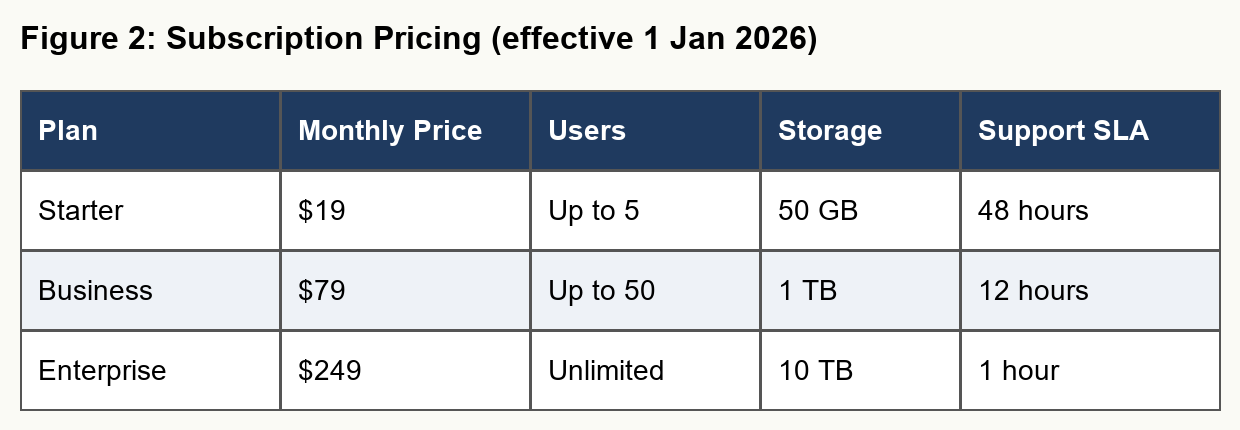

img-e2f3bd1751717f4c page 2 RAG_Table_Image_assets\img-e2f3bd1751717f4c.png


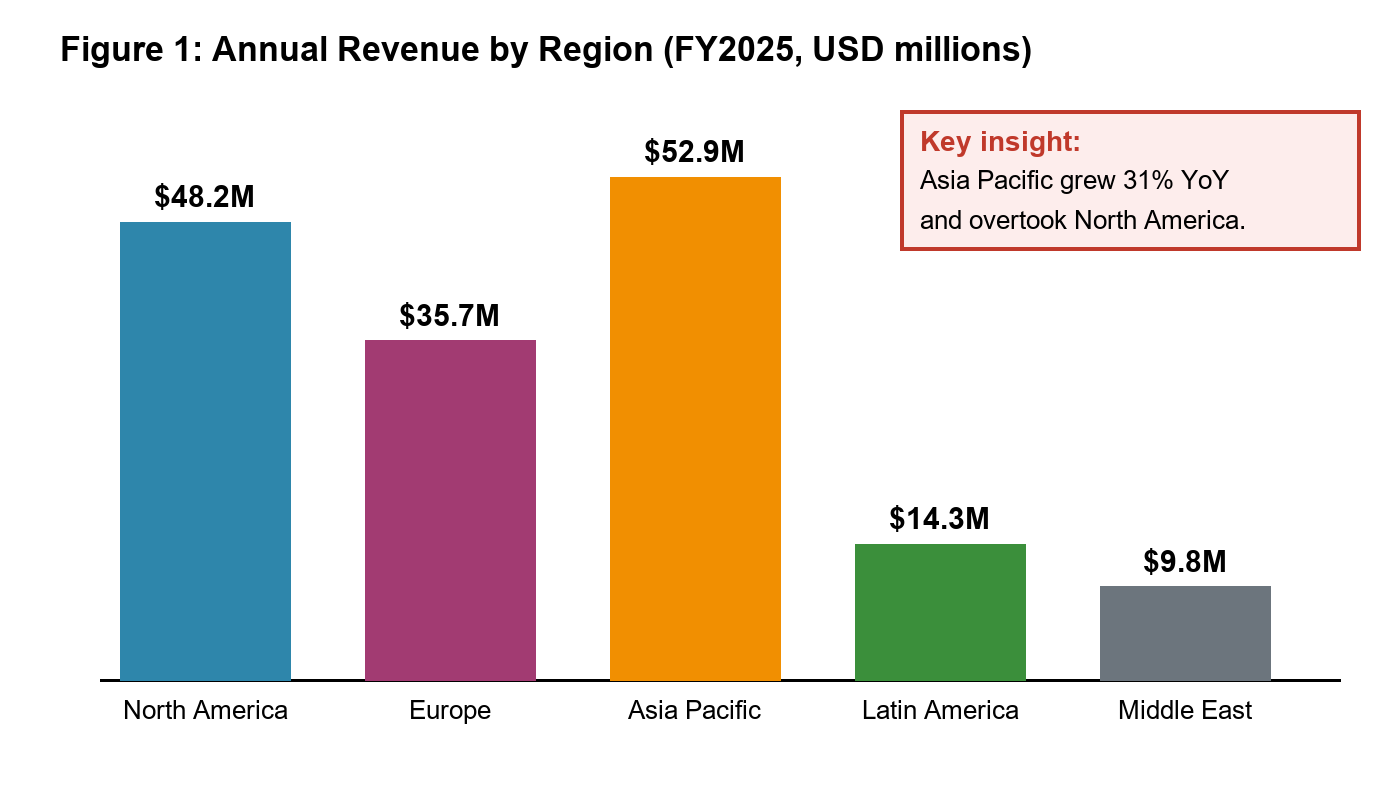

In [21]:
images = []   # dict per image: id, page, path
for page_no, page in enumerate(PdfReader(PDF_PATH).pages, start=1):
    for img in page.images:
        image_id = "img-" + hashlib.sha256(img.data).hexdigest()[:16]
        path = os.path.join(IMAGE_FOLDER, f"{image_id}.png")
        img.image.save(path, "PNG")
        images.append({"id": image_id, "page": page_no, "path": path})

for im in images:
    print(im["id"], "page", im["page"], im["path"])
    display(Image(filename=im["path"], width=500))

### Step 8: Describe images with Gemini vision
The description is what gets embedded, so it must contain every number and label.
Images already in Pinecone reuse their stored description, so Gemini is only called for new images.

In [23]:
DESCRIBE_PROMPT = """Describe this image from a business document so it can be found by search.
- Start with the image's title.
- If it is a chart, list every label and value shown.
- If it contains a table, transcribe the full table as a Markdown table.
- Include any notes or callouts.
Only describe what is visible in the image."""


def stored_description(image_id):
    res = index.fetch(ids=[f"{image_id}#0"], namespace=NAMESPACE)
    v = res.vectors.get(f"{image_id}#0")
    return v.metadata.get("description") if v else None


for im in images:
    im["description"] = stored_description(im["id"])
    if im["description"]:
        print(f"{im['id']}: description already in Pinecone, skipping Gemini")
    else:
        im["description"] = ask_llm([image_block(im["path"]), DESCRIBE_PROMPT]) or ""
        print(f"{im['id']}: described by Gemini")
    print(im["description"], "\n")

img-99ec1952a67956f6: described by Gemini
Figure 2: Subscription Pricing (effective 1 Jan 2026)

| Plan       | Monthly Price | Users      | Storage | Support SLA |
| :--------- | :------------ | :--------- | :------ | :---------- |
| Starter    | $19           | Up to 5    | 50 GB   | 48 hours    |
| Business   | $79           | Up to 50   | 1 TB    | 12 hours    |
| Enterprise | $249          | Unlimited  | 10 TB   | 1 hour      | 

img-e2f3bd1751717f4c: described by Gemini
Figure 1: Annual Revenue by Region (FY2025, USD millions)

This is a bar chart displaying annual revenue by region for fiscal year 2025, in USD millions.

*   **North America:** $48.2M
*   **Europe:** $35.7M
*   **Asia Pacific:** $52.9M
*   **Latin America:** $14.3M
*   **Middle East:** $9.8M

**Key insight:**
Asia Pacific grew 31% YoY
and overtook North America. 



### Step 9: Build the records
Every record has `type` (text / table / image) and `item_id`. Several vectors can share one `item_id`
(the rows of a table, the chunks of an image description), so any of them leads back to the same table or image.

In [24]:
records = []   # (id, text_to_embed, metadata)

for c in text_chunks:
    records.append((c["id"], c["text"], {
        "type": "text", "item_id": c["id"], "page": c["page"], "text": c["text"],
    }))

for t in tables:
    header, *body = t["rows"]
    table_meta = {"type": "table", "item_id": t["id"], "page": t["page"],
                  "title": t["title"], "table_markdown": t["markdown"]}
    # Summary vector: title + column names + first column values
    summary = f"{t['title']}. Columns: {', '.join(header)}. Rows: {', '.join(r[0] for r in body)}"
    records.append((f"{t['id']}#summary", summary, {**table_meta, "text": summary}))
    # One vector per row: "Column: value; Column: value ..."
    for r_no, row in enumerate(body, start=1):
        row_text = f"{t['title']}. " + "; ".join(f"{h}: {v}" for h, v in zip(header, row) if v)
        records.append((f"{t['id']}#row{r_no}", row_text, {**table_meta, "text": row_text}))

desc_splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=0, separators=["\n\n", "\n", " ", ""])
for im in images:
    for i, chunk in enumerate(desc_splitter.split_text(im["description"])):
        records.append((f"{im['id']}#{i}", chunk, {
            "type": "image", "item_id": im["id"], "page": im["page"],
            "image_path": im["path"], "description": im["description"], "text": chunk,
        }))

for rid, text, meta in records:
    print(f"{meta['type']:5} {rid}: {text[:80]}")

text  text-p1-0: Northwind Analytics - FY2025 Business Review
Sample document for testing retriev
text  text-p1-1: 2. Headcount and Budget by Department (Table 1)
Engineering is the largest depar
text  text-p2-0: 3. Regional Revenue (Figure 1 - image)
The chart below is an image. Its numbers 
table table-p1-1#summary: 2. Headcount and Budget by Department (Table 1). Columns: Department, Head, Empl
table table-p1-1#row1: 2. Headcount and Budget by Department (Table 1). Department: Engineering; Head: 
table table-p1-1#row2: 2. Headcount and Budget by Department (Table 1). Department: Sales; Head: Marcus
table table-p1-1#row3: 2. Headcount and Budget by Department (Table 1). Department: Marketing; Head: El
table table-p1-1#row4: 2. Headcount and Budget by Department (Table 1). Department: Customer Success; H
table table-p1-1#row5: 2. Headcount and Budget by Department (Table 1). Department: Finance; Head: Hann
table table-p1-1#row6: 2. Headcount and Budget by Department (Table 1). Departm

### Step 10: Embed and insert into Pinecone

In [25]:
vectors = embed([text for _, text, _ in records])

batch = [
    {"id": rid, "values": vectors[i].tolist(), "metadata": meta}
    for i, (rid, _, meta) in enumerate(records)
]
for start in range(0, len(batch), 100):
    index.upsert(vectors=batch[start:start + 100], namespace=NAMESPACE)

print(f"Inserted {len(batch)} vectors: "
      f"{len(text_chunks)} text chunks, {len(tables)} tables, {len(images)} images")

Inserted 13 vectors: 3 text chunks, 1 tables, 2 images


### Step 11: Retrieve
Search, then group matches by `item_id` so a table or image is returned once, as a whole.

In [26]:
def retrieve(question, top_k_items=3):
    res = index.query(
        vector=embed(question).tolist(),
        top_k=15,
        include_metadata=True,
        namespace=NAMESPACE,
    )
    items = {}
    for m in res.matches:   # matches come best first, so the first hit per item is its best score
        items.setdefault(m.metadata["item_id"], {**m.metadata, "score": m.score})
    return list(items.values())[:top_k_items]


def show(item):
    print(f"\n[{item['type'].upper()}] page {item['page']} | score {item['score']:.3f}")
    if item["type"] == "table":
        print(item["title"])
        display(Markdown(item["table_markdown"]))
    elif item["type"] == "image":
        display(Image(filename=item["image_path"], width=500))
    else:
        print(item["text"])


[IMAGE] page 2 | score 0.667


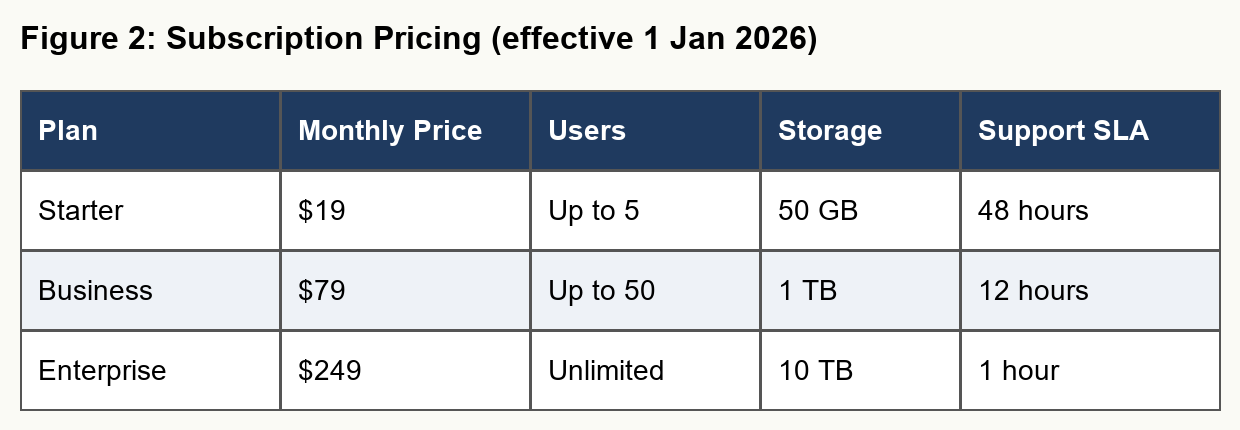


[TEXT] page 2 | score 0.563
3. Regional Revenue (Figure 1 - image)
The chart below is an image. Its numbers are not in the PDF text layer.
4. Pricing (Figure 2 - table inside an image)
This pricing table is a screenshot, so normal table extraction will not find it.

[TABLE] page 1 | score 0.395
2. Headcount and Budget by Department (Table 1)


| Department | Head | Employees | Budget (USD) | Location |
|---|---|---|---|---|
| Engineering | Priya Nair | 168 | $21,400,000 | Bengaluru |
| Sales | Marcus Lee | 92 | $11,750,000 | New York |
| Marketing | Elena Rossi | 47 | $6,200,000 | Milan |
| Customer Success | Tunde Okafor | 61 | $4,900,000 | Lagos |
| Finance | Hannah Kim | 22 | $2,300,000 | Seoul |
| HR | Diego Alvarez | 22 | $1,850,000 | Mexico City |
| Total |  | 412 | $48,400,000 |  |

In [27]:
for item in retrieve("Show me the subscription pricing table"):
    show(item)

### Step 12: Answer with Gemini
The retrieved text and tables go in as text; retrieved images are sent as the images themselves, so Gemini reads them directly.

In [28]:
def answer(question):
    items = retrieve(question)

    content = []
    for n, it in enumerate(items, start=1):
        if it["type"] == "image":
            content.append(f"[Source {n}] Image from page {it['page']}:")
            content.append(image_block(it["image_path"]))
        elif it["type"] == "table":
            content.append(f"[Source {n}] Table from page {it['page']}: {it['title']}\n{it['table_markdown']}")
        else:
            content.append(f"[Source {n}] Text from page {it['page']}:\n{it['text']}")

    content.append(f"""Answer the question using only the sources above.
Cite the source numbers you used, e.g. [Source 2]. Do not change any numbers.
If the sources don't contain the answer, say so.

Question: {question}""")

    reply = ask_llm(content) or "Sorry, I can't answer that question."

    print("Question:", question)
    print("\nAnswer:\n" + reply)
    print("\nSources:")
    for it in items:
        show(it)

Question about the native table (page 1)

In [29]:
answer("Who heads the Finance department and what is its budget?")

Question: Who heads the Finance department and what is its budget?

Answer:
Hannah Kim heads the Finance department, and its budget is $2,300,000. [Source 1]

Sources:

[TABLE] page 1 | score 0.569
2. Headcount and Budget by Department (Table 1)


| Department | Head | Employees | Budget (USD) | Location |
|---|---|---|---|---|
| Engineering | Priya Nair | 168 | $21,400,000 | Bengaluru |
| Sales | Marcus Lee | 92 | $11,750,000 | New York |
| Marketing | Elena Rossi | 47 | $6,200,000 | Milan |
| Customer Success | Tunde Okafor | 61 | $4,900,000 | Lagos |
| Finance | Hannah Kim | 22 | $2,300,000 | Seoul |
| HR | Diego Alvarez | 22 | $1,850,000 | Mexico City |
| Total |  | 412 | $48,400,000 |  |


[TEXT] page 1 | score 0.473
2. Headcount and Budget by Department (Table 1)
Engineering is the largest department, holding 44% of the total budget.

[TEXT] page 1 | score 0.384
Northwind Analytics - FY2025 Business Review
Sample document for testing retrieval on text, tables and images. Company and figures are fictional.
1. Summary
Northwind Analytics closed FY2025 with total revenue of $160.9 million and 412 employees across 7
offices. The headcount table below is a native PDF table, so its text can be extracted directly. The figures
on page 2 are images: their text can only be read with OCR or a vision model.
2. Headcount and Budget by Department (Table 1)


Question about the chart image (page 2)

In [ ]:
answer("Which region had the highest revenue in FY2025?")

Question about the table inside an image (page 2)

In [ ]:
answer("How much is the Business plan per month and what is its support SLA?")